<a href="https://colab.research.google.com/github/Huzaif005/Machine-Learning-/blob/main/Olakh.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install pandas scikit-learn matplotlib seaborn gradio

In [ ]:
import pandas as pd
import requests
import zipfile
import io

DATA_URL = (
    "https://archive.ics.uci.edu/static/public/"
    "228/sms+spam+collection.zip"
)

response = requests.get(DATA_URL, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
    with archive.open("SMSSpamCollection") as file:
        df = pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=["label", "message"],
            encoding="utf-8"
        )

df = df.dropna(subset=["label", "message"])
df["label"] = df["label"].str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()
df = df[df["label"].isin(["ham", "spam"])]
df = df[df["message"] != ""].drop_duplicates(subset=["message"])
df["target"] = df["label"].map({"ham": 0, "spam": 1})

print("Dataset loaded successfully!")
print("Total messages:", len(df))
display(df.head())
print(df["label"].value_counts())

Dataset loaded successfully!
Total messages: 5158


,label,message,target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


label
ham     4516
spam     642
Name: count, dtype: int64


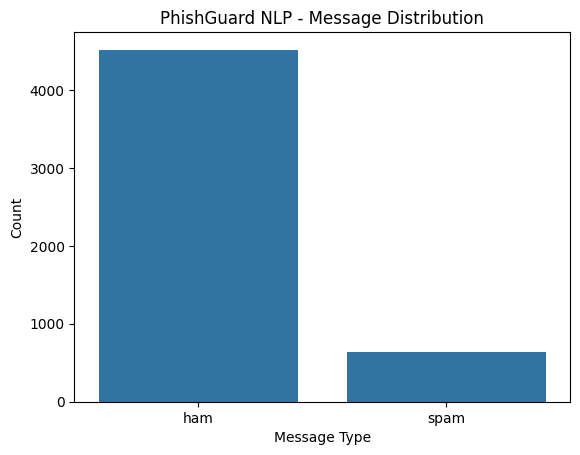

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="label")
plt.title("PhishGuard NLP - Message Distribution")
plt.xlabel("Message Type")
plt.ylabel("Count")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X_train, X_test, y_train, y_test = train_test_split(
    df["message"],
    df["target"],
    test_size=0.20,
    random_state=42,
    stratify=df["target"]
)

vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    max_features=20000,
    sublinear_tf=True
)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print("Training rows:", X_train_vec.shape[0])
print("Testing rows:", X_test_vec.shape[0])
print("Vocabulary size:", len(vectorizer.vocabulary_))

Training rows: 4126
Testing rows: 1032
Vocabulary size: 20000


In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_vec, y_train)

print("Model training completed!")

Model training completed!


Accuracy: 0.9758

Classification Report:

              precision    recall  f1-score   support

  Legitimate       0.99      0.98      0.99       904
        Spam       0.88      0.93      0.90       128

    accuracy                           0.98      1032
   macro avg       0.94      0.96      0.95      1032
weighted avg       0.98      0.98      0.98      1032



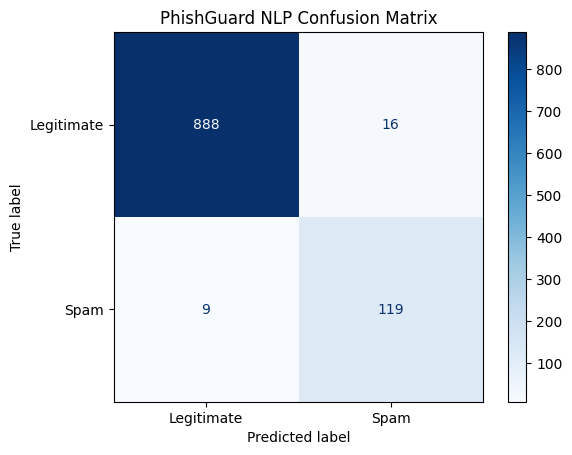

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

y_pred = model.predict(X_test_vec)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Spam"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Legitimate", "Spam"],
    cmap="Blues"
)
plt.title("PhishGuard NLP Confusion Matrix")
plt.show()

In [ ]:
def analyze_message(message):
    if not isinstance(message, str) or not message.strip():
        return {
            "Prediction": "Invalid input",
            "Spam probability": "N/A",
            "Warning": "Please enter a message."
        }

    features = vectorizer.transform([message])
    prediction = model.predict(features)[0]
    probabilities = model.predict_proba(features)[0]

    spam_index = list(model.classes_).index(1)
    spam_probability = probabilities[spam_index] * 100

    result = "SPAM" if prediction == 1 else "LEGITIMATE"

    return {
        "Prediction": result,
        "Spam probability": f"{spam_probability:.2f}%",
        "Warning": (
            "Potentially unwanted message. Verify independently."
            if prediction == 1
            else "Not classified as spam; this does not guarantee safety."
        )
    }

print(analyze_message(
    "Congratulations! You won a free prize. Click here to claim now!"
))

{'Prediction': 'SPAM', 'Spam probability': '93.30%', 'Warning': 'Potentially unwanted message. Verify independently.'}


In [ ]:
import gradio as gr

def frontend(message):
    result = analyze_message(message)

    return (
        result["Prediction"],
        result["Spam probability"],
        result["Warning"]
    )

with gr.Blocks(
    theme=gr.themes.Soft(),
    title="PhishGuard NLP"
) as demo:

    gr.Markdown("# 🛡️ PhishGuard NLP")
    gr.Markdown(
        "Analyze an SMS message using a machine-learning model."
    )

    message = gr.Textbox(
        label="Enter your message",
        placeholder="Paste an SMS message here...",
        lines=5
    )

    button = gr.Button("Analyze Message", variant="primary")

    prediction = gr.Textbox(label="Classification")
    probability = gr.Textbox(label="Estimated spam probability")
    warning = gr.Textbox(label="Interpretation")

    button.click(
        frontend,
        inputs=message,
        outputs=[prediction, probability, warning]
    )

demo.launch(share=True)

/tmp/ipykernel_3818/96206802.py:12: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2a45aaddddaed7cb86.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
